<a href="https://colab.research.google.com/github/Daria720/ML/blob/main/%D0%9B%D0%A08_%D0%93%D0%BE%D0%BC%D0%BE%D0%BD%D1%8E%D0%BA_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
X = iris.data

pd.DataFrame(X, columns=iris.feature_names).head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

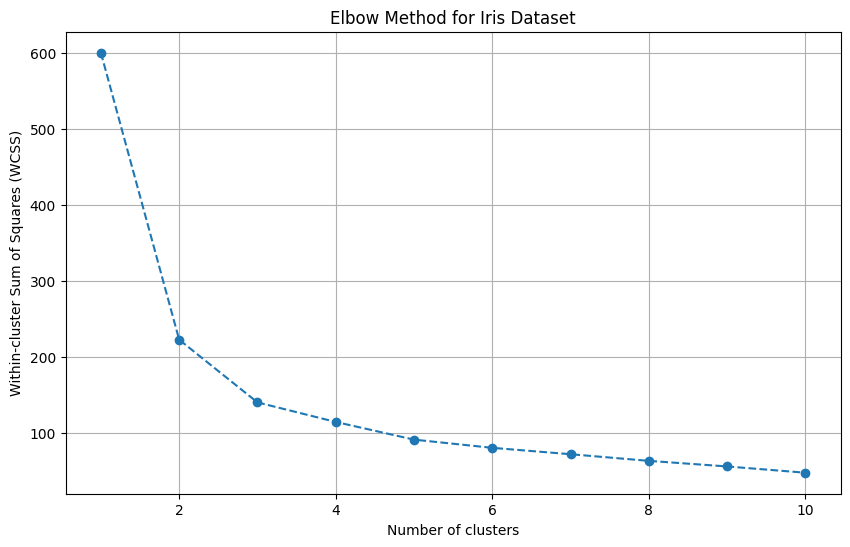

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_iris = pd.DataFrame(X_scaled, columns=iris.feature_names)

wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++',
                    max_iter=300, n_init=10, random_state=0)
    kmeans.fit(X_iris)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Iris Dataset')
plt.xlabel('Number of clusters')
plt.ylabel('Within-cluster Sum of Squares (WCSS)')
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

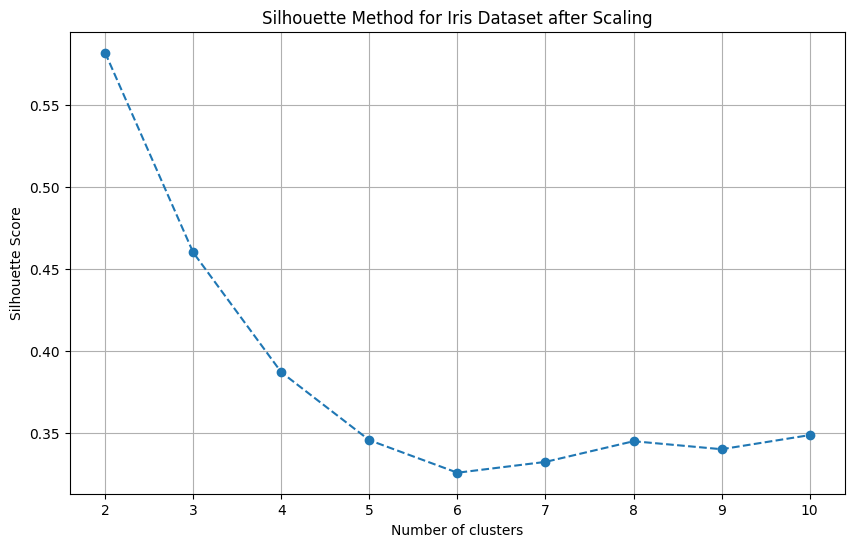

In [4]:
silhouette_scores = []
for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=0)
    cluster_labels = kmeans.fit_predict(X_iris)
    silhouette_avg = silhouette_score(X_iris, cluster_labels)
    silhouette_scores.append(silhouette_avg)

plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='--')
plt.title('Silhouette Method for Iris Dataset after Scaling')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

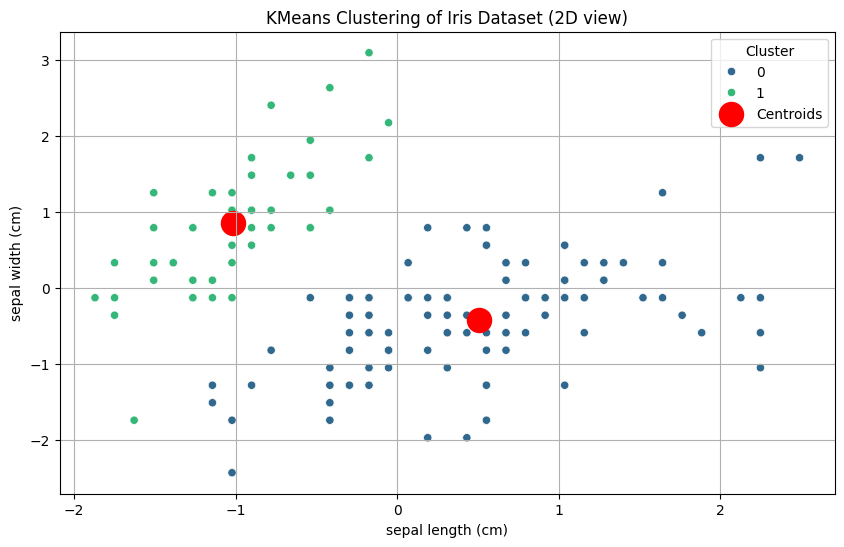

In [5]:
kmeans = KMeans(n_clusters=2, init='k-means++', max_iter=300, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_iris)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_iris.iloc[:, 0], y=X_iris.iloc[:, 1], hue=clusters,
                palette='viridis', legend='full')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            s=300, c='red', label='Centroids')
plt.title('KMeans Clustering of Iris Dataset (2D view)')
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.



Обидва методи вказують на те, що оптимальною кількістю кластерів є 2.

Метод силуетів: На графіку найвище значення метрики спостерігається саме для 2 кластерів (близько 0.58). Вищі значення вказують на кращу роздільність та щільність кластерів, тому цей метод однозначно рекомендує 2 кластери.   
Метод ліктя: На графіку спостерігається різке падіння суми квадратів відстаней  при переході від 1 до 2 кластерів, після чого графік стає більш пологим. Цей "вигин" (лікоть) на позначці 2 свідчить про те, що додавання наступних кластерів не дає значного покращення, тому вибір 2 кластерів є доцільним.  
 Отже, вибір двох кластерів повністю підтверджується результатами обох графічних методів оцінки.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
df = pd.read_csv(os.path.join(path, 'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
print("Назви стовпців:")
df.columns

Назви стовпців:


Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='object')

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [12]:
print("Перевірка наявності пропущених значень:")
df.isna().sum()

Перевірка наявності пропущених значень:


,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [13]:
print("Перевірка наявності дублікатів:")
df.duplicated().sum()

Перевірка наявності дублікатів:


np.int64(0)

**2.8. Описова статистика.** Виведіть основні описові статистики.

In [14]:
print("Описова статистика:")
df.describe()

Описова статистика:


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [15]:
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [19]:
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10]
}

rf = RandomForestClassifier(random_state=42)
grid_rf = GridSearchCV(rf, param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train, y_train)

print("Random Forest - Найкращі параметри:", grid_rf.best_params_)
print("Random Forest - Середня CV-точність:", grid_rf.best_score_)
print("Random Forest - Тестова accuracy:", accuracy_score(y_test, grid_rf.predict(X_test)))

Random Forest - Найкращі параметри: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Random Forest - Середня CV-точність: 0.9210709061829316
Random Forest - Тестова accuracy: 0.9102296450939458


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [21]:
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2']
}

lr = LogisticRegression(solver='saga', max_iter=2000, random_state=42, multi_class='multinomial')
grid_lr = GridSearchCV(lr, param_grid_lr, cv=5, scoring='accuracy', n_jobs=-1)
grid_lr.fit(X_train, y_train)

print("Logistic Regression - Найкращі параметри:", grid_lr.best_params_)
print("Logistic Regression - Середня CV-точність:", grid_lr.best_score_)
print("Logistic Regression - Тестова accuracy:", accuracy_score(y_test, grid_lr.predict(X_test)))

Logistic Regression - Найкращі параметри: {'C': 0.1, 'penalty': 'l1'}
Logistic Regression - Середня CV-точність: 0.8024113843588097
Logistic Regression - Тестова accuracy: 0.8183716075156576


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [22]:
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

svm = SVC(random_state=42)
grid_svm = GridSearchCV(svm, param_grid_svm, cv=5, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train, y_train)

print("SVM - Найкращі параметри:", grid_svm.best_params_)
print("SVM - Середня CV-точність:", grid_svm.best_score_)
print("SVM - Тестова accuracy:", accuracy_score(y_test, grid_svm.predict(X_test)))

SVM - Найкращі параметри: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
SVM - Середня CV-точність: 0.854677183437453
SVM - Тестова accuracy: 0.8496868475991649


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [23]:
results = {
    'Random Forest': {
        'Best Params': grid_rf.best_params_,
        'CV Score': grid_rf.best_score_,
        'Test Accuracy': accuracy_score(y_test, grid_rf.predict(X_test)),
        'Model': grid_rf
    },
    'Logistic Regression': {
        'Best Params': grid_lr.best_params_,
        'CV Score': grid_lr.best_score_,
        'Test Accuracy': accuracy_score(y_test, grid_lr.predict(X_test)),
        'Model': grid_lr
    },
    'SVM': {
        'Best Params': grid_svm.best_params_,
        'CV Score': grid_svm.best_score_,
        'Test Accuracy': accuracy_score(y_test, grid_svm.predict(X_test)),
        'Model': grid_svm
    }
}

results_df = pd.DataFrame(results).T
print("Порівняння моделей:")
print(results_df[['CV Score', 'Test Accuracy']])
print("\n")

best_model_name = results_df['CV Score'].astype(float).idxmax()
best_model = results[best_model_name]['Model']

print(f"Найкраща модель за CV-точністю: {best_model_name}")

y_pred_best = best_model.predict(X_test)
print(f"\nClassification Report для {best_model_name}:")
print(classification_report(y_test, y_pred_best))

Порівняння моделей:
                     CV Score Test Accuracy
Random Forest        0.921071       0.91023
Logistic Regression  0.802411      0.818372
SVM                  0.854677      0.849687


Найкраща модель за CV-точністю: Random Forest

Classification Report для Random Forest:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

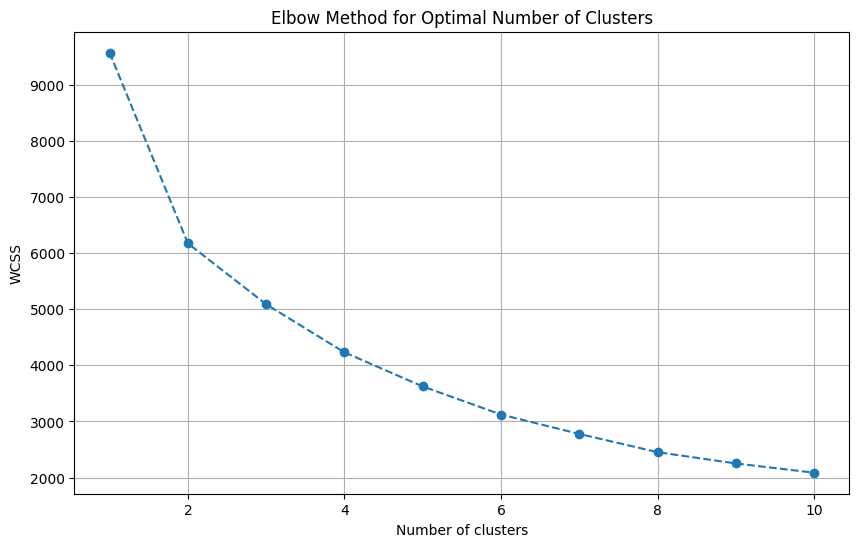

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features = df[['Age', 'StudyTimeWeekly', 'Absences', 'GPA']]

scaler = StandardScaler()
X_students_scaled = scaler.fit_transform(features)


wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X_students_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

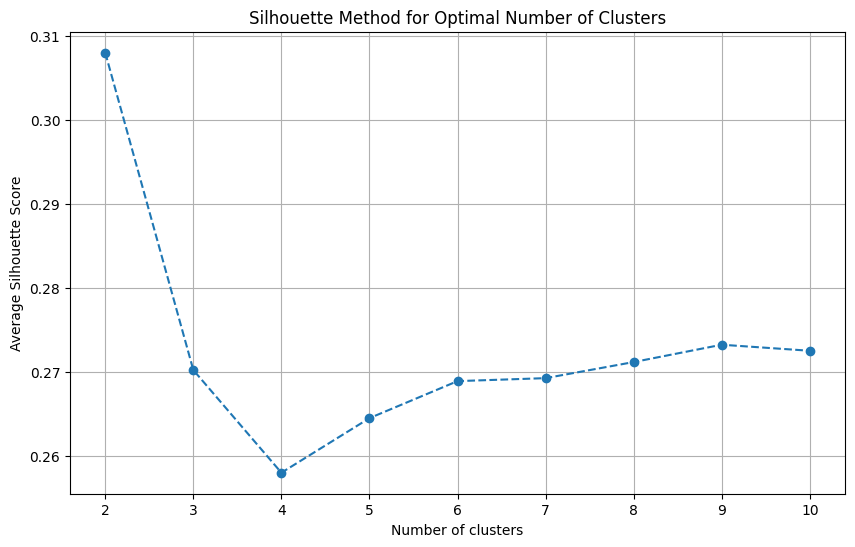

In [25]:
silhouette_scores = []
for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    cluster_labels = kmeans.fit_predict(X_students_scaled)
    silhouette_avg = silhouette_score(X_students_scaled, cluster_labels)
    silhouette_scores.append(silhouette_avg)

plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='--')
plt.title('Silhouette Method for Optimal Number of Clusters')
plt.xlabel('Number of clusters')
plt.ylabel('Average Silhouette Score')
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [26]:
%pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [27]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [28]:
X_all = df.drop(columns=['StudentID', 'GradeClass'])

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [29]:
X_all_scaled = StandardScaler().fit_transform(X_all)
pca = PCA(random_state=42).fit(X_all_scaled)
pve = pca.explained_variance_ratio_

**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

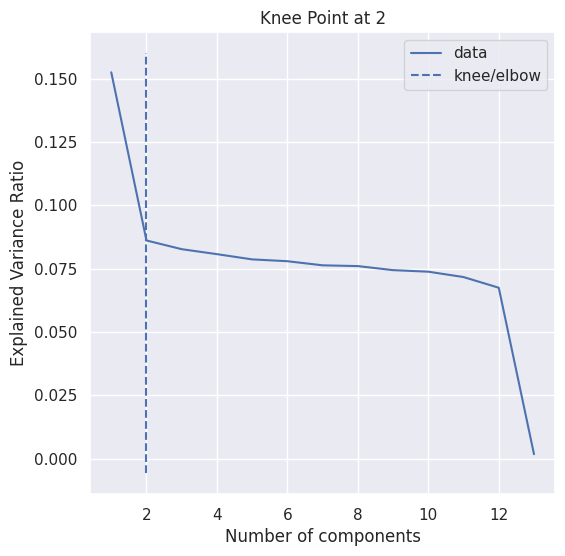

In [31]:
sns.set_theme()

kneedle = KneeLocator(
    x=range(1, len(pve) + 1),
    y=pve,
    curve='convex',
    direction='decreasing'
)

kneedle.plot_knee()
plt.title(f"Knee Point at {kneedle.elbow}" if kneedle.elbow is not None else "Knee Point not found")
plt.xlabel('Number of components')
plt.ylabel('Explained Variance Ratio')
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

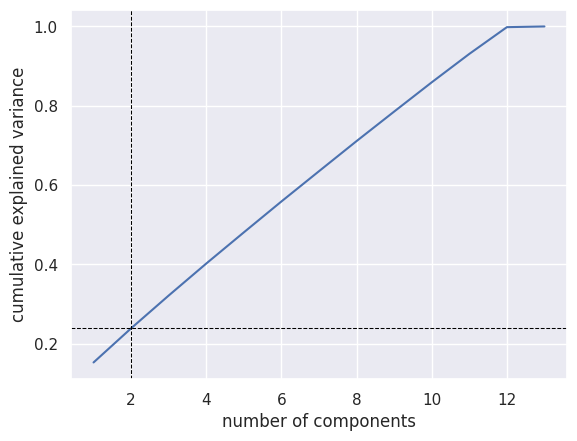

2 компонент пояснюють 23.86% дисперсії.


In [32]:
n_components = kneedle.elbow
if n_components is None:
    n_components = len(pve)
    print('Точку ліктя не знайдено: залишаємо всі головні компоненти.')

cumulative_variance = np.cumsum(pve)
ax = sns.lineplot(x=range(1, len(pve) + 1), y=cumulative_variance)

ax.axvline(x=n_components, c='black', linestyle='--', linewidth=0.75)
ax.axhline(y=cumulative_variance[n_components - 1], c='black', linestyle='--', linewidth=0.75)
ax.set(xlabel='number of components', ylabel='cumulative explained variance')
plt.grid(True)
plt.show()

print(f"{n_components} компонент пояснюють {cumulative_variance[n_components - 1]:.2%} дисперсії.")
X_pca = pca.transform(X_all_scaled)[:, :n_components]

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [33]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

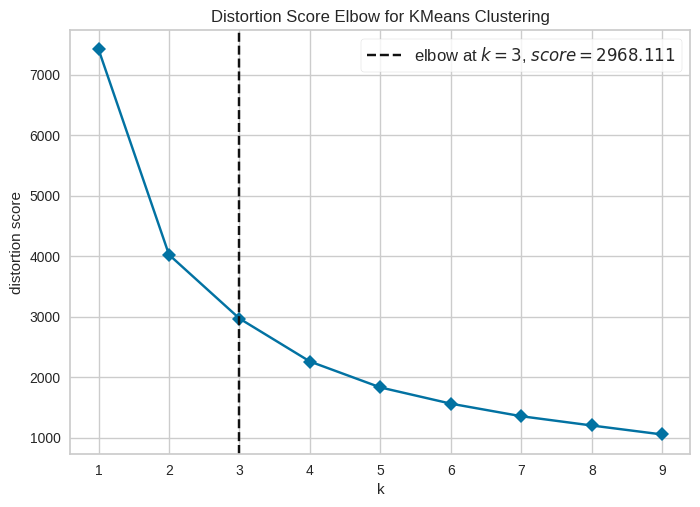

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [34]:
model_kmn = KMeans(n_init=10, random_state=42)

visualizer = KElbowVisualizer(
    model_kmn,
    k=(1, 10),
    timings=False
)

visualizer.fit(X_pca)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

##Висновок
Завдання 1:
Обидва методи показали 2 кластери. Хоча видів ірисів 3, два з них дуже схожі і зливаються, тому математично алгоритм бачить лише дві чіткі групи.

Завдання 2:
Класифікація vs Кластеризація: Класифікація — це робота з підказками: модель знала оцінки (GradeClass) і вчилася їх передбачати. Кластеризація — робота наосліп: оцінки прибрали, і алгоритм просто згрупував студентів за їхньою схожістю.
PCA (Головні компоненти): Скрипт автоматично знайшов оптимальну кількість компонент через KneeLocator. Мета — залишити найважливіші дані і викинути "шум". Після застосування методу PCA було обрано 2 головні компоненти, які пояснюють 23.86% дисперсії.